# Sheep APR Dataset Prep

Prepare the public Mendeley sheep facial-expression data for `openfarm-sheep-apr`.

Goals:
- verify and extract the source archive;
- compute the same blur audit used by the old notebook;
- add a lightweight duplicate/perceptual-hash audit;
- build explicit `train` / `test` and `train_raw` / `test_raw` splits;
- publish source-shaped image rows, not env-shaped prompts/messages.


In [1]:
#@title Setup dependencies and imports
!apt-get -qq update && apt-get -qq install -y unrar
!pip -q install datasets huggingface_hub opencv-python-headless pillow requests scikit-learn matplotlib seaborn

import hashlib
import json
import os
import re
import shutil
import subprocess
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from datasets import ClassLabel, Dataset, DatasetDict, Image
from huggingface_hub import HfApi, login
from IPython.display import display
from PIL import Image as PILImage, ImageDraw
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

sns.set_theme(style="whitegrid")


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)


In [2]:
#@title Configuration
WORK_DIR = "/content/openfarm_sheep_apr" #@param {type:"string"}
OUTPUT_REPO_ID = "oliveirabruno01/sheep-facial-expression-benchmark" #@param {type:"string"}
SEED = 42 #@param {type:"integer"}

BLUR_THRESHOLD = 2.5 #@param {type:"number"}
APPLY_EXACT_DHASH_DEDUP = False #@param {type:"boolean"}
TEST_FRACTION = 0.30 #@param {type:"number"}
RAW_TEST_FRACTION = 0.20 #@param {type:"number"}

PUSH_TO_HUB = True #@param {type:"boolean"}
HF_TOKEN_SECRET = "HF_TOKEN" #@param {type:"string"}

ROOT = Path(WORK_DIR)
RAW_DIR = ROOT / "raw"
PREPARED_DIR = ROOT / "prepared"
MEDIA_DIR = PREPARED_DIR / "images"
REPORT_DIR = PREPARED_DIR / "reports"
for path in [RAW_DIR, PREPARED_DIR, MEDIA_DIR, REPORT_DIR]:
    path.mkdir(parents=True, exist_ok=True)

RECORD_ID = "y5sm4smnfr"
SOURCE_URL = "https://data.mendeley.com/datasets/y5sm4smnfr"
SOURCE_DOI = "10.17632/y5sm4smnfr.5"
PAPER_DOI = "10.1016/j.compag.2020.105528"
SOURCE_ARCHIVE_NAME = "Sheep Facial Expression Dataset.rar"
LICENSE = "cc-by-4.0"
LABEL_NAMES = ["no_pain", "pain"]


In [3]:
#@title Download and verify Mendeley source

def request_json(url: str) -> dict:
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    return response.json()


def download_url(url: str, out_path: Path, expected_size: int | None = None) -> Path:
    if out_path.exists() and expected_size and out_path.stat().st_size == expected_size:
        return out_path
    out_path.parent.mkdir(parents=True, exist_ok=True)
    with requests.get(url, stream=True, timeout=120) as response:
        response.raise_for_status()
        total = int(response.headers.get("content-length", 0)) or expected_size
        with out_path.open("wb") as f, tqdm(total=total, unit="B", unit_scale=True, desc=out_path.name) as bar:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)
                    bar.update(len(chunk))
    return out_path


def sha256_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()

record = request_json(f"https://data.mendeley.com/public-api/datasets/{RECORD_ID}")
source_files = {f["filename"]: f for f in record["files"]}
if SOURCE_ARCHIVE_NAME not in source_files:
    raise FileNotFoundError(f"Expected {SOURCE_ARCHIVE_NAME} in Mendeley record files: {list(source_files)}")

archive_meta = source_files[SOURCE_ARCHIVE_NAME]
archive_path = RAW_DIR / SOURCE_ARCHIVE_NAME
download_url(
    archive_meta["content_details"]["download_url"],
    archive_path,
    expected_size=archive_meta.get("size"),
)

source_manifest = {
    "generated_at": datetime.now(timezone.utc).isoformat(),
    "source_url": SOURCE_URL,
    "source_doi": SOURCE_DOI,
    "paper_doi": PAPER_DOI,
    "license": record.get("data_licence", {}).get("short_name", "CC BY 4.0"),
    "archive_name": SOURCE_ARCHIVE_NAME,
    "archive_size": archive_path.stat().st_size,
    "archive_sha256": sha256_file(archive_path),
}
print(json.dumps(source_manifest, indent=2))


Sheep Facial Expression Dataset.rar:   0%|          | 0.00/142M [00:00<?, ?B/s]

{
  "generated_at": "2026-05-18T07:11:25.207592+00:00",
  "source_url": "https://data.mendeley.com/datasets/y5sm4smnfr",
  "source_doi": "10.17632/y5sm4smnfr.5",
  "paper_doi": "10.1016/j.compag.2020.105528",
  "license": "CC BY 4.0",
  "archive_name": "Sheep Facial Expression Dataset.rar",
  "archive_size": 141922726,
  "archive_sha256": "81cd851427becc4f58c3b209a6fee1a89b38c7209aba55bb1a09923950261945"
}


In [4]:
#@title Extract source images and build row table
extract_dir = RAW_DIR / "extracted"
if extract_dir.exists():
    shutil.rmtree(extract_dir)
extract_dir.mkdir(parents=True, exist_ok=True)
subprocess.run(["unrar", "x", "-o+", str(archive_path), str(extract_dir)], check=True)

label_dirs = {}
for directory in extract_dir.rglob("*"):
    if not directory.is_dir():
        continue
    normalized = re.sub(r"\s+", " ", directory.name.lower()).strip()
    if "no pain" in normalized:
        label_dirs["no_pain"] = directory
    elif "face pain" in normalized and "no pain" not in normalized:
        label_dirs["pain"] = directory

if set(label_dirs) != {"no_pain", "pain"}:
    raise ValueError(f"Could not identify sheep label directories: {label_dirs}")


def blur_score(path: Path) -> float:
    image = cv2.imread(str(path))
    if image is None:
        raise ValueError(f"Could not decode image: {path}")
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    return float(cv2.Laplacian(gray, cv2.CV_64F).var())


def dhash(path: Path, hash_size: int = 8) -> str:
    image = PILImage.open(path).convert("L").resize((hash_size + 1, hash_size), PILImage.Resampling.LANCZOS)
    pixels = np.asarray(image)
    bits = pixels[:, 1:] > pixels[:, :-1]
    value = 0
    for bit in bits.flatten():
        value = (value << 1) | int(bit)
    return f"{value:0{hash_size * hash_size // 4}x}"

records = []
for label_name, directory in label_dirs.items():
    for image_path in sorted(directory.iterdir()):
        if image_path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
            continue
        records.append({
            "image_source_path": str(image_path),
            "label": LABEL_NAMES.index(label_name),
            "label_name": label_name,
            "source_filename": image_path.name,
            "blur_score": blur_score(image_path),
            "dhash": dhash(image_path),
            "source_url": SOURCE_URL,
            "source_doi": SOURCE_DOI,
            "source_paper_doi": PAPER_DOI,
            "license": LICENSE,
        })

df = pd.DataFrame(records)
print("raw rows:", len(df))
print("raw label counts:", Counter(df["label_name"]))
display(df.groupby("label_name")["blur_score"].describe())


raw rows: 1123
raw label counts: Counter({'no_pain': 979, 'pain': 144})


,count,mean,std,min,25%,50%,75%,max
label_name,,,,,,,,
no_pain,979.0,36.282145,239.713594,0.999982,2.607508,3.941760,10.779789,5387.921307
pain,144.0,23.660067,62.950182,1.497388,2.797545,3.983782,15.221875,625.555120


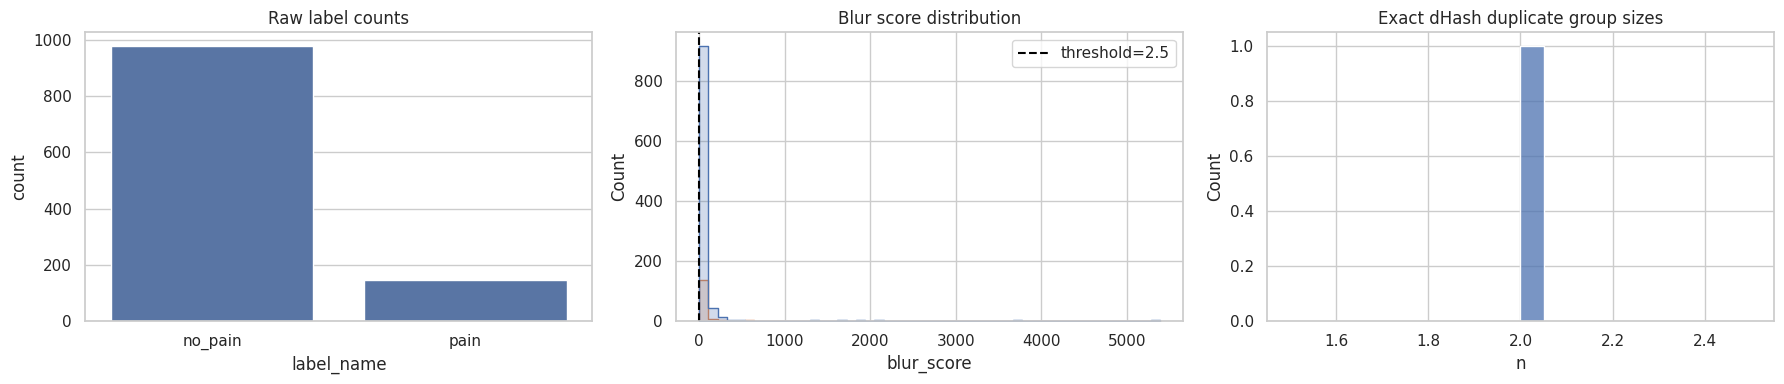

saved: /content/openfarm_sheep_apr/prepared/reports/sheep_quality_audit.png
exact dHash duplicate groups: 1


,label_name,dhash,n
264,no_pain,4e6db3a7a3230747,2


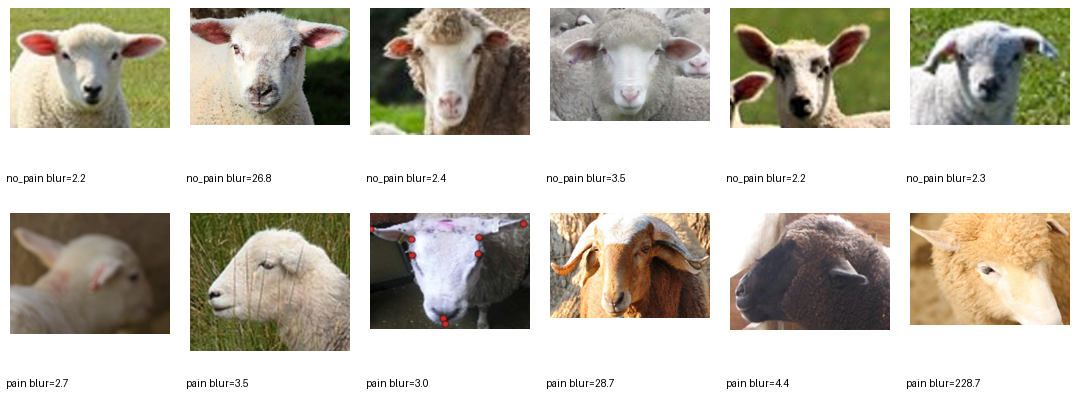

saved: /content/openfarm_sheep_apr/prepared/reports/sheep_examples.jpg


In [5]:
#@title Visual audit: examples, blur, and perceptual duplicates
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.countplot(data=df, x="label_name", ax=axes[0])
axes[0].set_title("Raw label counts")

sns.histplot(data=df, x="blur_score", hue="label_name", bins=50, element="step", ax=axes[1])
axes[1].axvline(BLUR_THRESHOLD, color="black", linestyle="--", label=f"threshold={BLUR_THRESHOLD}")
axes[1].set_title("Blur score distribution")
axes[1].legend()

duplicate_groups = df.groupby(["label_name", "dhash"]).size().reset_index(name="n")
duplicate_groups = duplicate_groups[duplicate_groups["n"] > 1].sort_values("n", ascending=False)
sns.histplot(duplicate_groups["n"] if len(duplicate_groups) else [], bins=20, ax=axes[2])
axes[2].set_title("Exact dHash duplicate group sizes")
plt.tight_layout()
audit_path = REPORT_DIR / "sheep_quality_audit.png"
plt.savefig(audit_path, dpi=160, bbox_inches="tight")
plt.show()
print("saved:", audit_path)
print("exact dHash duplicate groups:", len(duplicate_groups))
display(duplicate_groups.head(12))

sample_rows = []
for label_name, group in df.groupby("label_name"):
    sample_rows.extend(group.sample(n=min(6, len(group)), random_state=SEED).to_dict("records"))
thumbs = []
for row in sample_rows:
    image = PILImage.open(row["image_source_path"]).convert("RGB")
    image.thumbnail((160, 160))
    canvas = PILImage.new("RGB", (180, 205), "white")
    canvas.paste(image, ((180 - image.width) // 2, 8))
    draw = ImageDraw.Draw(canvas)
    draw.text((6, 172), f"{row['label_name']} blur={row['blur_score']:.1f}", fill=(0, 0, 0))
    thumbs.append(canvas)

cols = 6
sheet = PILImage.new("RGB", (cols * 180, int(np.ceil(len(thumbs) / cols)) * 205), (245, 245, 245))
for i, thumb in enumerate(thumbs):
    sheet.paste(thumb, ((i % cols) * 180, (i // cols) * 205))
display(sheet)
examples_path = REPORT_DIR / "sheep_examples.jpg"
sheet.save(examples_path, quality=92)
print("saved:", examples_path)


In [6]:
#@title Build cleaned balanced train/test and raw train/test views

def stratified_split(frame: pd.DataFrame, test_fraction: float, seed: int):
    train_df, test_df = train_test_split(
        frame,
        test_size=test_fraction,
        random_state=seed,
        shuffle=True,
        stratify=frame["label_name"],
    )
    return train_df.reset_index(drop=True), test_df.reset_index(drop=True)

clean_df = df[df["blur_score"] >= BLUR_THRESHOLD].copy()
if APPLY_EXACT_DHASH_DEDUP:
    clean_df = (
        clean_df.sort_values("blur_score", ascending=False)
        .drop_duplicates(["label_name", "dhash"], keep="first")
        .reset_index(drop=True)
    )

class_counts = Counter(clean_df["label_name"])
n_per_class = min(class_counts.values())
balanced_df = (
    clean_df.groupby("label_name", group_keys=False)
    .sample(n=n_per_class, random_state=SEED)
    .sample(frac=1, random_state=SEED)
    .reset_index(drop=True)
)

train_df, test_df = stratified_split(balanced_df, TEST_FRACTION, SEED)
train_raw_df, test_raw_df = stratified_split(df, RAW_TEST_FRACTION, SEED)

split_frames = {
    "train": train_df,
    "test": test_df,
    "train_raw": train_raw_df,
    "test_raw": test_raw_df,
}

print("clean rows after blur/dhash policy:", len(clean_df), Counter(clean_df["label_name"]))
print("balanced clean rows:", len(balanced_df), Counter(balanced_df["label_name"]))
for split_name, frame in split_frames.items():
    print(split_name, len(frame), Counter(frame["label_name"]))


clean rows after blur/dhash policy: 885 Counter({'no_pain': 762, 'pain': 123})
balanced clean rows: 246 Counter({'no_pain': 123, 'pain': 123})
train 172 Counter({'no_pain': 86, 'pain': 86})
test 74 Counter({'no_pain': 37, 'pain': 37})
train_raw 898 Counter({'no_pain': 783, 'pain': 115})
test_raw 225 Counter({'no_pain': 196, 'pain': 29})


In [7]:
#@title Materialize image paths and build Hugging Face DatasetDict preview
for split_name, frame in split_frames.items():
    split_dir = MEDIA_DIR / split_name
    if split_dir.exists():
        shutil.rmtree(split_dir)
    split_dir.mkdir(parents=True, exist_ok=True)
    frame = frame.copy().reset_index(drop=True)
    image_paths = []
    for i, row in frame.iterrows():
        out_path = split_dir / f"sheep_apr_{split_name}_{i:05d}.jpg"
        shutil.copy2(row["image_source_path"], out_path)
        image_paths.append(str(out_path))
    frame["image"] = image_paths
    split_frames[split_name] = frame

PUBLIC_COLUMNS = [
    "image",
    "label",
    "label_name",
    "blur_score",
    "dhash",
    "source_filename",
    "source_url",
    "source_doi",
    "source_paper_doi",
    "license",
]
FORBIDDEN_COLUMNS = {"openfarm_id", "task_id", "messages", "prompt", "answer"}

hf_splits = {}
for split_name, frame in split_frames.items():
    overlap = FORBIDDEN_COLUMNS.intersection(frame.columns)
    if overlap:
        raise ValueError(f"Forbidden public columns in {split_name}: {sorted(overlap)}")
    for image_path in frame["image"].sample(n=min(10, len(frame)), random_state=SEED):
        PILImage.open(image_path).verify()
    dataset = Dataset.from_pandas(frame[PUBLIC_COLUMNS], preserve_index=False)
    dataset = dataset.cast_column("image", Image())
    dataset = dataset.cast_column("label", ClassLabel(names=LABEL_NAMES))
    hf_splits[split_name] = dataset

hf_dataset = DatasetDict(hf_splits)
print(hf_dataset)
print(hf_dataset["train"][0])


Casting the dataset:   0%|          | 0/172 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/74 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/898 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/225 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label', 'label_name', 'blur_score', 'dhash', 'source_filename', 'source_url', 'source_doi', 'source_paper_doi', 'license'],
        num_rows: 172
    })
    test: Dataset({
        features: ['image', 'label', 'label_name', 'blur_score', 'dhash', 'source_filename', 'source_url', 'source_doi', 'source_paper_doi', 'license'],
        num_rows: 74
    })
    train_raw: Dataset({
        features: ['image', 'label', 'label_name', 'blur_score', 'dhash', 'source_filename', 'source_url', 'source_doi', 'source_paper_doi', 'license'],
        num_rows: 898
    })
    test_raw: Dataset({
        features: ['image', 'label', 'label_name', 'blur_score', 'dhash', 'source_filename', 'source_url', 'source_doi', 'source_paper_doi', 'license'],
        num_rows: 225
    })
})
{'image': <PIL.Image.Image image mode=RGB size=1024x787 at 0x79C91243B740>, 'label': 0, 'label_name': 'no_pain', 'blur_score': 47.54661671952331, 'dhash': 'dc7571b3f6

In [8]:
#@title Dataset card scaffold
summary = {
    "generated_at": datetime.now(timezone.utc).isoformat(),
    "source_manifest": source_manifest,
    "splits": {split: int(hf_dataset[split].num_rows) for split in hf_dataset},
    "raw_label_counts": dict(Counter(df["label_name"])),
    "clean_label_counts": dict(Counter(clean_df["label_name"])),
    "balanced_label_counts": dict(Counter(balanced_df["label_name"])),
    "blur_threshold": BLUR_THRESHOLD,
    "apply_exact_dhash_dedup": APPLY_EXACT_DHASH_DEDUP,
    "exact_dhash_duplicate_groups": int(len(duplicate_groups)),
}
manifest_path = PREPARED_DIR / "source_manifest.json"
manifest_path.write_text(json.dumps(summary, indent=2))

card = f"""---
license: cc-by-4.0
task_categories:
- image-classification
language:
- en
tags:
- animal-welfare
- sheep
- facial-expression
- pain-assessment
- spfes
---

# Sheep Facial Expression Benchmark

Prepared OpenFARM sheep facial-expression benchmark data from the public Mendeley Data record `{SOURCE_DOI}`.

## Source

- Source dataset: {SOURCE_URL}
- Source DOI: `{SOURCE_DOI}`
- Related paper DOI: `{PAPER_DOI}`
- License: CC BY 4.0

## Splits

```json
{json.dumps(summary['splits'], indent=2)}
```

`train` and `test` are filtered/balanced views for benchmark and training use. `train_raw` and `test_raw` preserve the natural source class distribution.

## Processing Notes

- Blur score is the variance of the Laplacian.
- The cleaned views use `BLUR_THRESHOLD={BLUR_THRESHOLD}`.
- Exact perceptual duplicate removal by label is `{APPLY_EXACT_DHASH_DEDUP}`.
- Rows are source-shaped image records. Prompts, instructions, and env-specific context are rendered by OpenFARM environments.

## Caveat

The source labels are normal/no-pain vs abnormal/pain facial-expression proxy labels from public images. Treat them as a visual pain-expression benchmark, not a full clinical pain diagnosis dataset.
"""
card_path = PREPARED_DIR / "README.md"
card_path.write_text(card)
print("wrote:", manifest_path)
print("wrote:", card_path)
print(card[:1200])


wrote: /content/openfarm_sheep_apr/prepared/source_manifest.json
wrote: /content/openfarm_sheep_apr/prepared/README.md
---
license: cc-by-4.0
task_categories:
- image-classification
language:
- en
tags:
- animal-welfare
- sheep
- facial-expression
- pain-assessment
- spfes
---

# Sheep Facial Expression Benchmark

Prepared OpenFARM sheep facial-expression benchmark data from the public Mendeley Data record `10.17632/y5sm4smnfr.5`.

## Source

- Source dataset: https://data.mendeley.com/datasets/y5sm4smnfr
- Source DOI: `10.17632/y5sm4smnfr.5`
- Related paper DOI: `10.1016/j.compag.2020.105528`
- License: CC BY 4.0

## Splits

```json
{
  "train": 172,
  "test": 74,
  "train_raw": 898,
  "test_raw": 225
}
```

`train` and `test` are filtered/balanced views for benchmark and training use. `train_raw` and `test_raw` preserve the natural source class distribution.

## Processing Notes

- Blur score is the variance of the Laplacian.
- The cleaned views use `BLUR_THRESHOLD=2.5`.
- Exact perc

In [10]:
#@title Optional push to Hugging Face Hub
if PUSH_TO_HUB:
    token = os.environ.get(HF_TOKEN_SECRET)
    if token:
        login(token=token)
    else:
        try:
            from google.colab import userdata
            token = userdata.get(HF_TOKEN_SECRET)
            login(token=token)
        except Exception as exc:
            raise RuntimeError(f"Set {HF_TOKEN_SECRET} in env or Colab secrets before pushing.") from exc

    hf_dataset.push_to_hub(OUTPUT_REPO_ID, private=False)
    HfApi().upload_file(
        path_or_fileobj=str(PREPARED_DIR / "README.md"),
        path_in_repo="README.md",
        repo_id=OUTPUT_REPO_ID,
        repo_type="dataset",
    )
    print("pushed:", f"https://huggingface.co/datasets/{OUTPUT_REPO_ID}")
else:
    print("PUSH_TO_HUB is False. Review the preview, manifest, and dataset card before publishing.")


Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Map:   0%|          | 0/172 [00:00<?, ? examples/s]

Creating parquet from Arrow format:   0%|          | 0/2 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

...

Creating parquet from Arrow format:   0%|          | 0/3 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              :  14%|#3        | 3.84MB / 27.6MB            

pushed: https://huggingface.co/datasets/oliveirabruno01/sheep-facial-expression-benchmark
